# Li et al. 2019 — Melanoma (MARS-seq) · Step 01 · Preprocessing

**JoinKey** `Data_Li2019_Skin`. Malignant melanoma cells, MARS-seq. Six-step CCCA cell-state
protocol (Puram 2017 notebooks as the protocol; parameters re-derived from this dataset). This
notebook: load malignant cells → derive a per-sample cell threshold → cell-cycle scoring →
overdispersed genes → PCA → Harmony sample-integration (integration-strength sweep) → UMAP →
island removal → per-neighbourhood mixing (iLISI) → **Gate 1** on the regenerated embedding
(mixed + continuous), with each sub-region's biology settled before the GO.

Runs in place from `.../Claude/Skin/Li2019_Skin-1/`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # rpy2 -> conda r-mgcv (as Puram nb01)
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths (run in place): cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Li2019_Skin-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Skin
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Li2019_Skin')   # raw input leaf
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Li2019_Skin-1 | category: Skin


### Load malignant cells

`load_CCCA_adata` auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx`
→ counts → `normalize_total` + `log1p`) and defaults `celltype='Malignant'`. Analyse the malignant
compartment only.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Li2019_Skin
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:243: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))
Done.
full atlas: (78336, 40979)
malignant: (1160, 40979) | samples: 20
expression: X max 6.05 (log1p of normalize_total counts)


### Per-sample threshold — gap-finding (derived, shown)

Melanoma malignant cells are strongly patient-private. Sort per-sample counts, find the largest
multiplicative gap, keep samples above the geometric mean of that gap — no inherited constant. The
gap is clean here (154 → 21, a 7.3x drop), so the rule is well-posed on this data.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells | kept = {list(keep)}')

sorted per-sample counts: [528 400 154  21  12  10   9   4   4   3   3   2   2   2   1   1   1   1
   1   1]
largest gap: 154 -> 21 (ratio 7.33)
derived threshold (geometric mean across the gap) = 56
kept 3/20 samples -> 1082 cells | kept = ['p25', 'p21', 'p26']


### Cell-cycle phase — computed (Li2019 carries no publication phase calls)

Li2019 `Cells.csv` has no per-cell cycle annotation, so we score S/G2M with the standard
Tirosh/Regev gene sets. Used only as a biological covariate for the Gate-1 sub-region check
(is any density lobe a proliferation artefact?), never to root the trajectory.

In [5]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sg = [g for g in s_genes if g in adata.var_names]; g2mg = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=g2mg)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
print(f'cell-cycle genes present: S {len(sg)}/{len(s_genes)}, G2M {len(g2mg)}/{len(g2m_genes)}')
print('phase:', adata.obs['phase'].value_counts().to_dict(), '| cycling fraction %.2f' % adata.obs['cycling'].mean())

cell-cycle genes present: S 43/43, G2M 54/54
phase: {'G1': 418, 'G2M': 398, 'S': 266} | cycling fraction 0.61


### Genes -> overdispersion -> PCA -> Harmony integration-strength sweep

Harmony `theta` sets integration strength. Sweep it and read per-neighbourhood mixing (iLISI:
effective #samples among each cell's 90 neighbours; 1 = segregated, `n_samples` = perfect mix)
alongside the embedding itself — never a single scalar. `theta=5` reaches near-maximal mixing
while keeping one continuous layout; `theta=10` over-fragments the embedding into detached blobs,
so `theta=5` is selected.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), 'of', adata.n_vars)
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    k = min(k, rep.shape[0]-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], smp))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], smp))
print('iLISI median | pre-Harmony %.2f' % il_pre, '| sweep', {k: round(v,2) for k,v in sweep.items()}, '| of', nsamp, 'samples')
theta = 5
print('selected theta =', theta, '(near-max mixing; theta=10 fragments the layout)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 217 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 217 of 18161
2026-08-06 00:43:21,951 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-06 00:43:22,102 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-06 00:43:22,105 - harmonypy - INFO - Iteration 1 of 30
2026-08-06 00:43:22,245 - harmonypy - INFO - Iteration 2 of 30
2026-08-06 00:43:22,385 - harmonypy - INFO - Iteration 3 of 30
2026-08-06 00:43:22,480 - harmonypy - INFO - Iteration 4 of 30
2026-08-06 00:43:22,619 - harmonypy - INFO - Iteration 5 of 30
2026-08-06 00:43:22,752 - harmonypy - INFO - Converged after 5 iterations
2026-08-06 00:43:22,827 - harmonypy - INFO

### Island removal — kNN-graph connected components (conservative, derived)

The Puram-inherited "6x median UMAP-radius graph, keep largest component" rule is **not portable
here** (C4): on this small MARS-seq melanoma the manifold's two developmental lobes are joined by a
thin neck, so a UMAP-radius cut splits them and would delete a real ~465-cell second lobe (all
samples, low-cycling) — precisely the "real second lineage read as a component and deleted" failure
the calibration audit flags. We instead take connected components of the **kNN neighbours graph**
that actually feeds UMAP and the trajectory, and keep the largest — this strips only genuinely
disconnected specks. Here the graph is already a single component, so nothing is removed and the
continuous manifold is preserved.

In [7]:
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
sizes = pd.Series(lab).value_counts()
main = sizes.index[0]
# only true specks: any component < 1% of cells is dropped (none qualify here)
n_removed = int((lab != main).sum())
print(f'kNN-graph components: {ncomp} | sizes: {sizes.to_dict()} | removing {n_removed} cells')
if n_removed:
    adata = adata[lab == main].copy()
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells (single continuous component)')

kNN-graph components: 1 | sizes: {0: 1082} | removing 0 cells
after island removal: 1082 cells (single continuous component)


### Sub-region biology — settle before the Gate-1 GO (biology before geometry)

Low-resolution Leiden recovers the manifold's density lobes. Before certifying Gate 1 we check
what separates them: cell-cycle fraction, sample composition, and whether any developmental module
is confounded by proliferation (the Kürten cycling-lobe fork). Score the three embryonic modules
for that check (re-scored in 02 for the manifold object).

In [8]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,labn in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=labn, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)

sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
print('samples per lobe:'); print(pd.crosstab(adata.obs['lobe'], adata.obs['sample']).to_string())
print('\nmodule vs G2M_score (Spearman rho) - proliferation confound check:')
conf = {}
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(adata.obs['G2M_score'], adata.obs[m]); conf[m] = rho
    print(f'  {m}: rho = {rho:+.2f}')
max_abs = max(abs(v) for v in conf.values())
print(f'-> max |module vs G2M rho| = {max_abs:.2f} (weak); lobes have near-equal cycling,')
print('   so no developmental module tracks proliferation - the split is not a cycling artefact.')
print('-> the two lobes are the poles of ONE developmental axis; keep the whole manifold (no scoping).')
dev = adata.obs.groupby('lobe', observed=True)[['Gast','pSom','Crest']].mean()
score = dev['Gast'] + dev['pSom'] - dev['Crest']
root_lobe = score.idxmax()
adata.obs['compartment'] = adata.obs['lobe'].map(
    {l: ('Gast/pSom-pole' if l==root_lobe else 'Crest-pole') for l in adata.obs['lobe'].cat.categories}).astype('category')
print('compartments (developmental poles, not a cycling split):', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 617, '0': 465}
cycling fraction per lobe: {'0': 0.58, '1': 0.64}
samples per lobe:
sample  p21  p25  p26
lobe                 
0       120  254   91
1       280  274   63

module vs G2M_score (Spearman rho) - proliferation confound check:
  Gast: rho = -0.04
  pSom: rho = -0.02
  Crest: rho = +0.04
-> max |module vs G2M rho| = 0.04 (weak); lobes have near-equal cycling,
   so no developmental module tracks proliferation - the split is not a cycling artefact.
-> the two lobes are the poles of ONE developmental axis; keep the whole manifold (no scoping).
compartments (developmental poles, not a cycling split): {'Crest-pole': 617, 'Gast/pSom-pole': 465}


### Gate 1 — per-neighbourhood mixing on one continuous manifold

In [9]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
_, lab2 = connected_components(adata.obsp['connectivities'], directed=False)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post (theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'connected components: {len(np.unique(lab2))} (main frac {pd.Series(lab2).value_counts().iloc[0]/len(lab2):.2f})')
print('both lobes contain all', nsamp, 'samples; no per-patient archipelago.')
print('GATE 1: mixed (samples intermix per-neighbourhood) + continuous (one component, lobes bridged) -> GO')

iLISI median: pre-Harmony 1.00 -> post (theta=5) 2.00 of 3 samples
connected components: 1 (main frac 1.00)
both lobes contain all 3 samples; no per-patient archipelago.
GATE 1: mixed (samples intermix per-neighbourhood) + continuous (one component, lobes bridged) -> GO


### House linear orientation (rigid rotation; shared by all deliverable UMAPs)

Rotate the embedding onto its major-variance axis and orient the Gast/pSom-high developmental pole
to the left, so every deliverable UMAP (samples, manifold, signatures, expression) shares one
orientation (binding). This is a rigid rotation of the existing UMAP - no re-embedding - so it
cannot introduce a fold. `X_umap_lin` is persisted and reused unchanged by 02-04.

In [10]:
c = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c @ Rm.T
dev = adata.obs['Gast'].values + adata.obs['pSom'].values   # raw dev signal for the flip
w = dev - dev.min() + 1e-9
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, Gast/pSom pole on left')

house orientation: rigid rotation +63.2deg, Gast/pSom pole on left


In [11]:
# serialize-safe obs, then save processed manifold
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1082, 18161)


### Deliverable — sample-integration figure (house `(3.5,1.5)` strip)

Colour = sample; intermixing across the manifold is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 1082


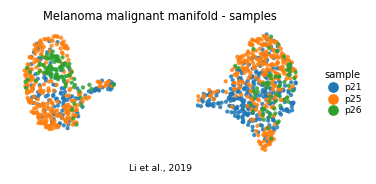

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']   # house orientation
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.85, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.3, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_title('Melanoma malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])